# SQUID JPA (twpa-sim `squid_jpa`), flux-pumped, rebuilt in the Quantcore PDK

**What it is.** A lumped JPA whose inductor is a DC SQUID: the static flux tunes the mode, and a pump on the flux
line at twice the signal frequency modulates the SQUID inductance — three-wave mixing, phase-preserving gain in
reflection, with the pump far from the signal band (Yamamoto et al. 2008; Roy & Devoret 2016).

**Source.** twpa-sim (S. Mandal, MIT), `src/twpa/layout/generate.py`, family `squid_jpa`
(`examples/layout/squid_jpa.json`: two 2 µm junctions in a loop, branch height 20 µm, a 12 × 12 µm MIM shunt) on
its illustrative process (I_c 20 µA and C_J 240 fF per junction, 144 fF MIM). twpa-sim leaves the coupling and the
flux line external. Read-only clone `build/external/twpa-sim` (rev 05abc83), never run.

| | twpa-sim source | Quantcore rebuild (why) |
|---|---|---|
| SQUID | two 2 × 2 µm overlap JJs (40 µA total), loop 20 µm high | the **largest PDK trilayer SQUID** (two 2 × 2 µm fingers, I_c,tot 1.3 µA, L_s(0) 0.25 nH), junctions ±8 µm apart; flagged `pdk_rn` |
| shunt C | MIM 144 fF | interdigital island–ground capacitor ≈ 1.6 pF (f0 ≈ 7 GHz with the PDK SQUID) |
| coupling, flux | external | KQC `FingerCapacitorSquare` snapped to the island lead; a shorted flux / pump CPW past the SQUID's ground side (`flux_line`, 2 µm ground strip, as QPDK's pump) |
| f0 | ≈ 70 GHz with the illustrative values | ≈ 7 GHz |
| chip | none | 7.5 × 7.5 mm PDK die, signal and flux `BondPad`s 100 µm from the edge |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the 7.5 mm die, the signal and flux bond pads, the signal feed with its
coupling capacitor, the SQUID JPA (the nonlinear element: a SQUID shunted by an interdigital capacitor, with its flux
line), the flux / pump line, and then the whole chip (the sim group, the save). Then the same steps as the Flow strip
of the Quantcore KLayout plugin: **Check** (DRC, netlist) → **LOM** (the amplifier's circuit models, their plots, one
change by hand) → **Simulate** (export to HFSS, the Q3D C-matrix of the JPA, the eigenmode simulation with the SQUID
as a lumped inductor, the full-wave run on the eigenmode's mesh settings) → **Results** (the eigenmodes plotted, f0, κ
and the Kerr read off, FEM against the LOM, a feedback step and the iteration to the rebuild's own aim, 7 GHz at zero
flux) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in four cells, with its outputs) is kept as `twpa_sim_squid_jpa.v1.ipynb`; both save the same
`twpa_sim_squid_jpa.json`. The v1 notebook saves the file twice, the second time after its flux sweep has left
`flux_phi0: 0.0` (the cell's default) in the SQUID JPA's parameters; here that value is in the layout call, and the
sweep and the by-hand change (LOM 1, LOM 3) work on copies.

## Setup

The imports, the output folder and the switches. `_amplifiers` holds the amplifier notebooks' helpers (the PDK
facts, value tables, plots, the linear S-parameters of a LOM netlist, and the readers that put kept FEM results in
amplifier terms); `_common` the helpers all design notebooks share (tables, snapshots, the PDK placement, the FEM and
feedback steps). The physics is `quantcore_circuits.analysis.amplifiers`, the cells
`quantcore_circuits.layouts.others.amplifiers`.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
import os, sys
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *
from _amplifiers import pdk_facts_md, plot, show_md, table_md
from _amplifiers import jpa_mode, reflection_values   # v2: kept FEM results in amplifier terms (Results)
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.layouts.others.amplifiers import LumpedJpa, drawn_junction_values
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the film's kinetic inductance, the cheese and the 3/0
keep-outs. For this chip that means: the 7.5 mm die with the QCT frame, the two bond pads 100 µm from the west and
east edges, and the largest SQUID the PDK finger range allows (two 2 × 2 µm trilayer junctions, I_c,tot 1.3 µA): far
outside the qubit R_n window (flagged `pdk_rn`, not retuned) and far below twpa-sim's illustrative 40 µA, so the shunt
capacitor is planar and ≈ 1.6 pF for a ≈ 7 GHz mode.

In [4]:
show_md(pdk_facts_md(PDK))

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

# Design: the layout, one segment at a time

An amplifier chip is laid out the way a designer would do it by hand: the die, the bond pads, the feed (and pump)
line, the nonlinear element, the routing, and then the whole chip. Each segment is one cell with one picture of the
chip so far (and, live, KLayout redraws after every cell). A route always joins two ports, so a line is drawn once
both of its ends exist. The line under each picture counts what is on the chip; it says 0 qubits: an amplifier has
none, its junctions sit inside the amplifier cell (counted among the other components).

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm die with the QCT frame |
| 2 | the signal `BondPad` (west) and the flux / pump `BondPad` (east, 500 µm below the signal axis) |
| 3 | the signal feed: the coupling capacitor `CC` and the 50 Ω line `L_SIG` from the signal pad to it |
| 4 | the nonlinear element: the PDK SQUID (drawn against the source's), then the SQUID JPA `JS` (a `LumpedJpa` with a SQUID and a flux line), snapped to the capacitor |
| 5 | the routing: the flux / pump line `L_FLUX`, the SQUID's flux port → the east pad |
| 6 | the whole chip: the sim group, the save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip: a standard 7.5 × 7.5 mm Quantcore die, on which the PDK draws the
**QCT frame** — the L dicing markers, the corner marker areas, the chip boundary and the device ID (`name_chip`
"SQJPA") on a free edge. `YC` is the die's mid-height: the signal axis.

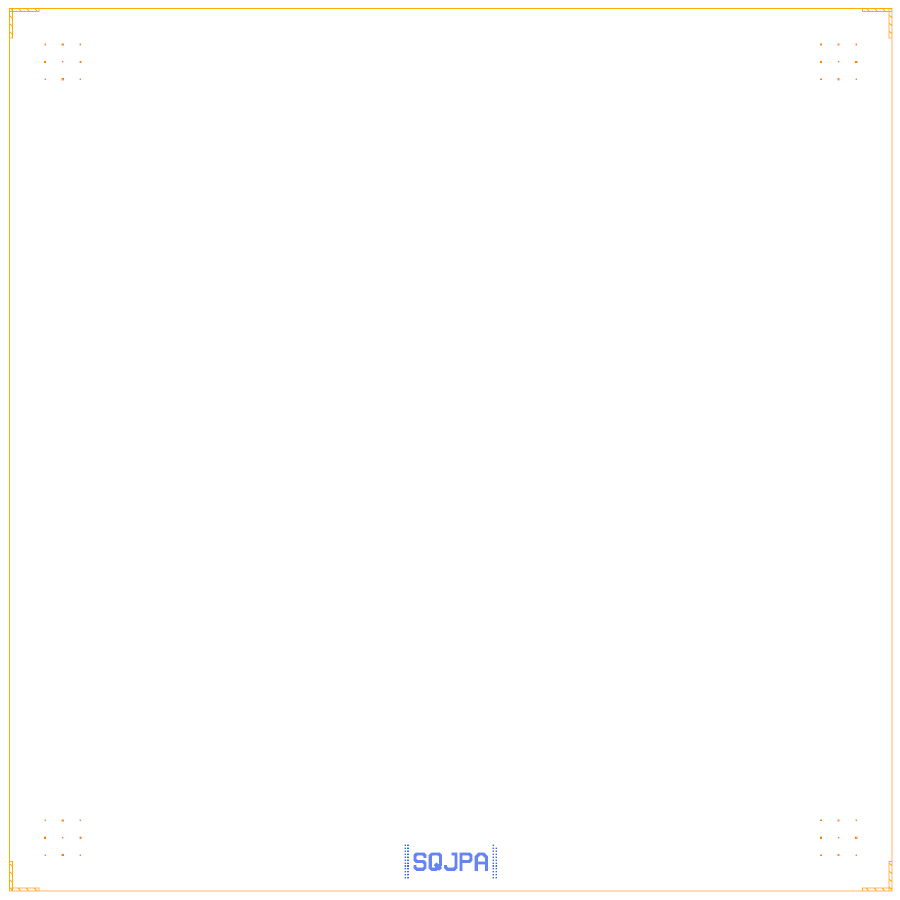

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/twpa_sim_squid_jpa_s1_die.png')

In [5]:
W = H = 7500
YC = 3750
d = Designer("twpa_sim_squid_jpa", box=(0, 0, W, H), chip={"name_chip": "SQJPA"}, live=LIVE)
layout_step(d, OUT / "twpa_sim_squid_jpa_s1_die.png", size=(900, 900), width=400)

## Design 2 · Bond pads (the 100 µm rule)
The signal pad on the west edge, the flux / pump pad on the east edge. `edge="auto"` slides each pad perpendicular to
its die edge until its outer etch is the PDK `pad_edge` (100 µm) from it. The flux pad sits 500 µm below the signal
axis, where the flux line from the SQUID arrives (Design 5).

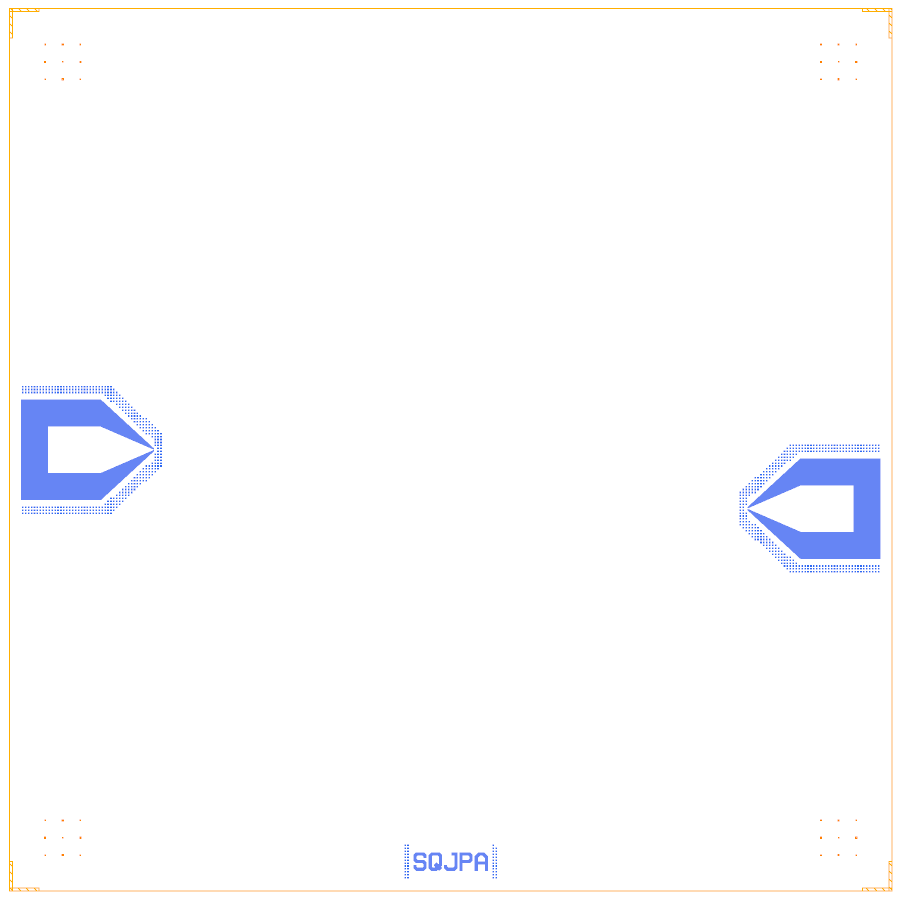

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `P_SIG`, `P_FLUX`.

WindowsPath('examples/designs/amplifiers/twpa_sim_squid_jpa_s2_pads.png')

In [6]:
with d.batch():
    d.add("P_SIG", "BondPad", at=(400, YC), rot=-90, edge="auto")
    d.add("P_FLUX", "BondPad", at=(7100, YC - 500), rot=90, edge="auto")
layout_step(d, OUT / "twpa_sim_squid_jpa_s2_pads.png", size=(900, 900), width=400)

## Design 3 · The signal feed: the coupling capacitor and its line

The JPA is used in reflection: the signal comes in from `P_SIG`, meets the JPA through the coupling capacitor and
leaves the same way. `CC` is KQC's `FingerCapacitorSquare` (14 fingers × 90 µm, 5 µm wide, 3 µm gaps); `L_SIG` is the
plain 50 Ω feed from the pad to its port `a`. Both need nothing else on the chip, so they come first; the JPA is
snapped to the capacitor's other port in Design 4. The pump comes through the flux line (Design 5).

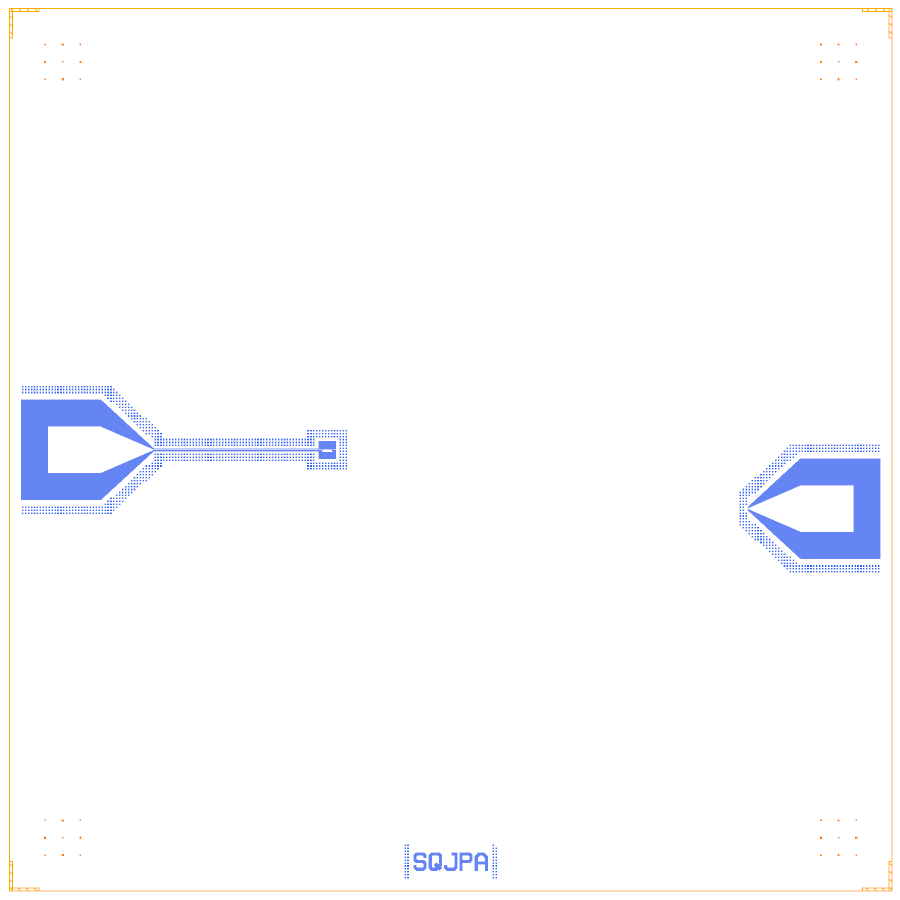

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `CC` and 1 route(s) `L_SIG`.

WindowsPath('examples/designs/amplifiers/twpa_sim_squid_jpa_s3_feed.png')

In [7]:
with d.batch():
    d.add("CC", "FingerCapacitorSquare", at=(2700, YC), finger_number=14, finger_length=90, finger_width=5,
          finger_gap=3)
    d.route("L_SIG", "P_SIG.a", "CC.a")
layout_step(d, OUT / "twpa_sim_squid_jpa_s3_feed.png", size=(900, 900), width=400)

## Design 4 · The nonlinear element: the SQUID JPA

**The SQUID.** twpa-sim's illustrative SQUID (two 2 × 2 µm overlap junctions, 40 µA in all) is beyond the PDK rule:
the largest the PDK finger range allows is two 2 × 2 µm trilayer junctions (`BIG_JJ`). `drawn_junction_values` gives
the drawn SQUID's L_s(0) and C_J from the PDK; the table puts it next to the source's (and shows why twpa-sim's own
values give ≈ 70 GHz). `JUNCTION` goes on the instance: the LOM uses it, the DRC flags its `pdk_rn`, the eigenmode job
draws it as a lumped inductor.

**The JPA.** `JS` (`LumpedJpa`, `junction_type="Quantcore Squid"`, `flux_line=True`): the island IDC (45 fingers per
side, 180 µm), the trilayer SQUID across the 16 µm gap at the far end (its straight fingers on the island's landing
head, its bent fingers on the 2 µm ground strip), the shorted flux CPW beyond it. Its lead (port `signal`) is snapped
to the coupling capacitor's port `b` (Design 3). `flux_phi0` is the static bias the LOM uses (Φ0). `flux_phi0=0.0` is
in the call: the design file has it (the cell's default; the v1 notebook's flux sweep wrote it before its last save),
so the saved file stays the same.

The first picture is the chip so far, the second zooms on the JPA (the capacitor, the island's fingers, the SQUID, the
flux line).

In [8]:
BIG_JJ = {"finger_width": 2.0, "second_finger_width": 2.0}
LS0, CJ, _ = drawn_junction_values("Quantcore Squid", BIG_JJ)
JUNCTION = {"Lj_nH": LS0, "Cj_fF": CJ}
ls_src = amp.lj_from_ic(40e-6) * 1e9
f_src = 1 / (2 * np.pi * np.sqrt(ls_src * 1e-9 * (480 + 144) * 1e-15)) / 1e9
show_md(table_md(["SQUID", "I_c,tot (µA)", "L_s(0) (nH)", "C_J (fF)", "device R_n (kΩ)"], [
    ["drawn: 2 × trilayer 2.0 × 2.0 µm", amp.ic_from_lj(LS0 * 1e-9) * 1e6, LS0, CJ, rn_from_lj(LS0) / 1e3],
    ["twpa-sim illustrative", 40.0, ls_src, 480.0, rn_from_lj(ls_src) / 1e3]])
    + f"\n\ntwpa-sim's own values: f0 ≈ {f_src:.0f} GHz (illustrative).")

| SQUID | I_c,tot (µA) | L_s(0) (nH) | C_J (fF) | device R_n (kΩ) |
|---|---|---|---|---|
| drawn: 2 × trilayer 2.0 × 2.0 µm | 1.303 | 0.2525 | 400 | 1.687 |
| twpa-sim illustrative | 40 | 0.008228 | 480 | 0.05498 |

twpa-sim's own values: f0 ≈ 70 GHz (illustrative).

C_shunt ≈ 1590 fF (analytic IDC)

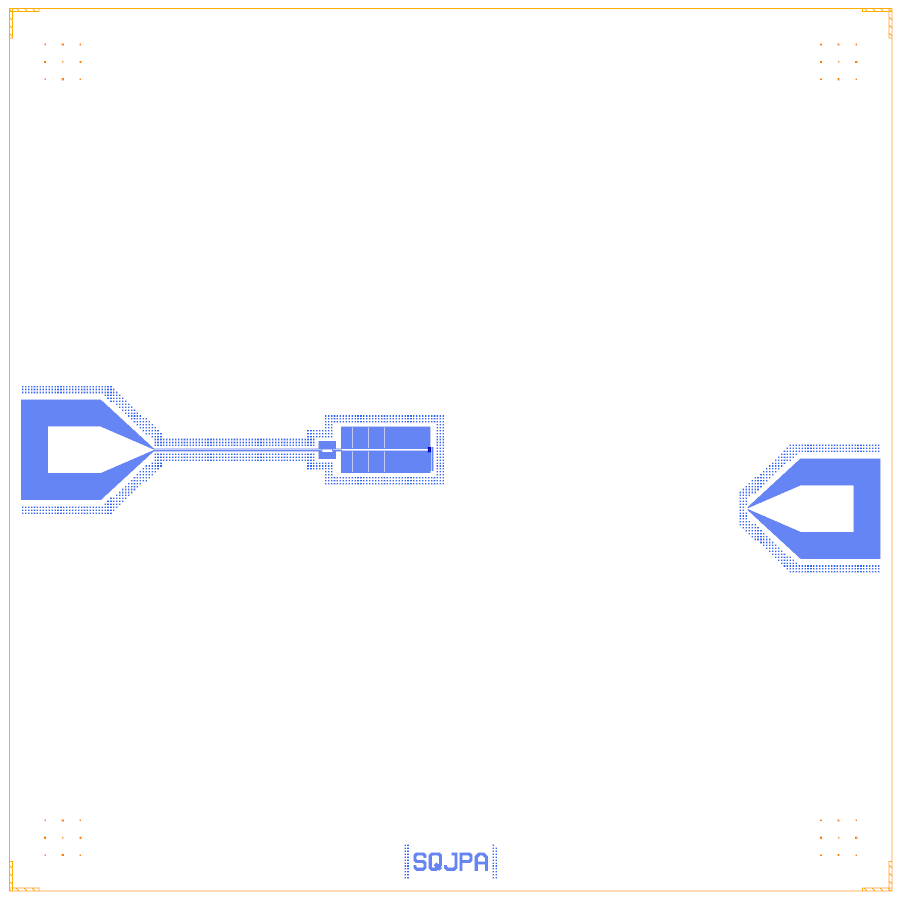

**On the chip so far:** 2 pads · 0 qubits · 2 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `JS`.

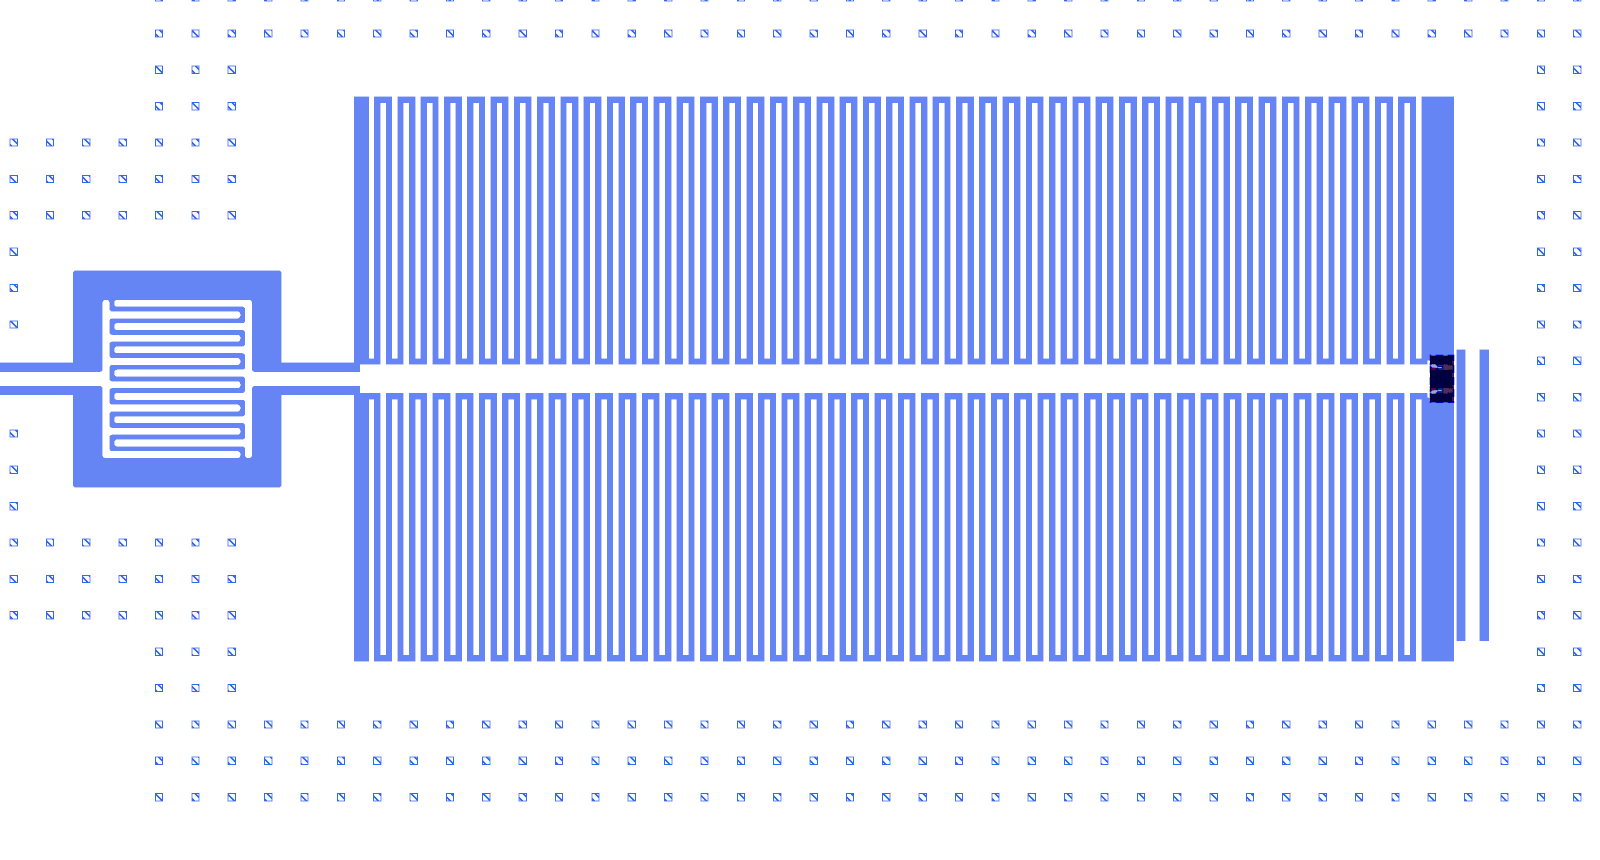

WindowsPath('examples/designs/amplifiers/twpa_sim_squid_jpa_s4_device.png')

In [9]:
SHUNT = dict(shunt_fingers=45, finger_length=180, finger_width=4, finger_gap=4)
with d.batch():
    js = d.add("JS", "LumpedJpa", snap="signal", to="CC.b", junction_type="Quantcore Squid", flux_line=True,
               junction=JUNCTION, junction_params=BIG_JJ, **SHUNT, flux_phi0=0.0)
show_md(f"C_shunt ≈ {LumpedJpa.qcc_values(js.spec['params'])['C_shunt_fF']:.0f} fF (analytic IDC)")
layout_step(d, OUT / "twpa_sim_squid_jpa_s4_squid_jpa.png", size=(900, 900), width=400)
xd, yd = port_xy(d, "CC.a")                      # the JPA starts at its coupling capacitor
snap(d, OUT / "twpa_sim_squid_jpa_s4_device.png", box=(xd - 50, yd - 330, xd + 1050, yd + 260), size=(1600, 860),
     width=640)

## Design 5 · Routing: the flux / pump line
The flux line `L_FLUX` from the SQUID's flux port (facing south) to the east pad — it
carries the static bias and the pump at 2 f0. (The signal feed `L_SIG` came in Design 3.)

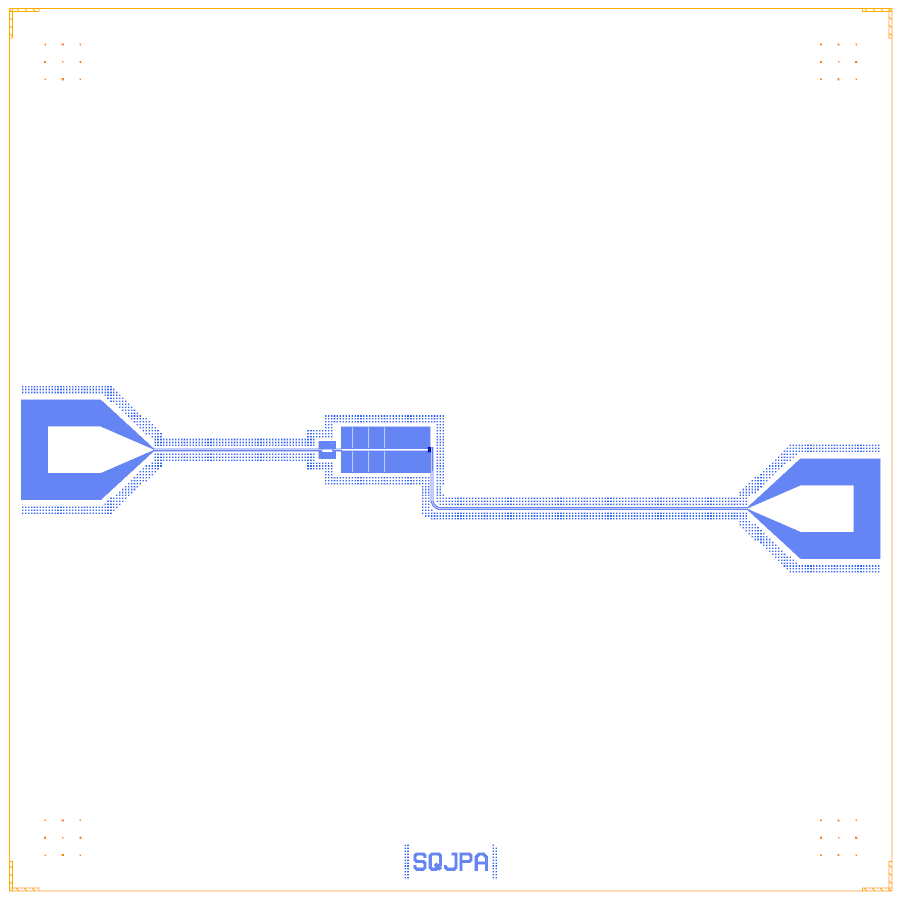

**On the chip so far:** 2 pads · 0 qubits · 2 other components · 2 routes · 0 declared couplings. **This step added** 1 route(s) `L_FLUX`.

WindowsPath('examples/designs/amplifiers/twpa_sim_squid_jpa_s5_flux.png')

In [10]:
with d.batch():
    xf, yf = port_xy(d, "JS.flux")
    d.route("L_FLUX", "JS.flux", "P_FLUX.a", nodes=[(xf, YC - 500)], r=80)
layout_step(d, OUT / "twpa_sim_squid_jpa_s5_flux.png", size=(900, 900), width=400)

## Design 6 · The whole chip: the sim group, the save

**Sim group.** `jpa`: the capacitor and the JPA with a 100 µm margin, for a Q3D C-matrix and an eigenmode job; the
signal feed and the flux line are cut at the box edge. The design sets no targets (Results 4 puts one on a copy).

**No centring.** The flux pad 500 µm below the signal axis puts the content off-centre in y; the v1 leaves it there
(Check 1's `pdk_report` measures it).

**Save.** `save_design` writes `twpa_sim_squid_jpa.json` and compares it with the file it replaces (the previous
run's, e.g. the `.v1` notebook's): with `flux_phi0=0.0` in the layout call it should say *same design*. The picture is
the whole chip.

**Same design as before:** `examples/designs/amplifiers/twpa_sim_squid_jpa.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer twpa_sim_squid_jpa: 4 instances, 2 routes, live=False> → examples\designs\amplifiers\twpa_sim_squid_jpa.json


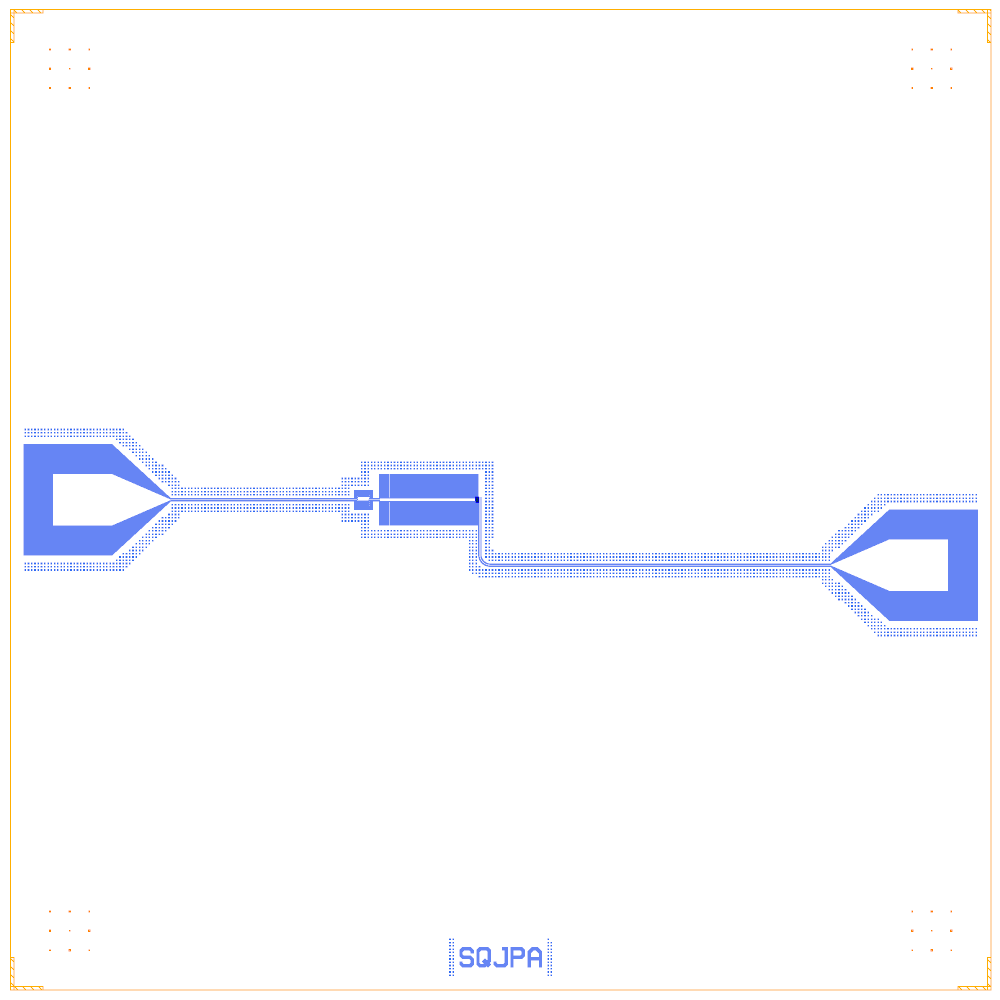

**On the chip so far:** 2 pads · 0 qubits · 2 other components · 2 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/twpa_sim_squid_jpa_s6_chip.png')

In [11]:
d.sim_group("jpa", ["CC", "JS"], margin_um=100, analyses=["q3d_cmatrix", "eigenmode_epr"])
if not LIVE:
    d.show()
DESIGN, same = save_design(d, OUT / "twpa_sim_squid_jpa.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "twpa_sim_squid_jpa_s6_chip.png", size=(1000, 1000), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC
`pdk_rn` flags the SQUID's device R_n (≈ 1.7 kΩ against the qubit window): an amplifier SQUID, as designed.

Expected here (from the v1 run): no errors, two `dangling_port` warnings (`JS.squid_a`, `JS.squid_b`: the junction
ends) and `pdk_rn` on `JS` (L_J 0.2525 nH); content centre − die centre (+0, −250) µm.

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip box
and the frame: **errors** would block fab, **warnings** are layout hints, **PDK design warnings** (`pad_edge`,
`pdk_rn`, …) flag a PDK margin and are never fixed by retuning. `pdk_report(d)` sums up the PDK side.

In [ ]:
print(d.drc())
show_md(pdk_report(d))

## Check 2 · Netlist
The island node carries C_shunt and the `SQUID` branch (L_s0, C_J, `flux_phi0`); `CC` couples it to the pad node;
the flux line is a control (`flux_bias` on `J_JS`), no circuit element.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The circuit models

QuCat's normal mode of the lumped circuit, then (a) its flux tuning and (b) the flux-pumped gain at the operating
point; the plots are in LOM 2. The flux sweep runs on a non-live copy of the design (`design_copy`): the design, and
KLayout, stay at Φ = 0 (the v1 swept the design itself and set it back).

**(a)** QuCat modes at zero flux, then the static flux bias swept through `flux_phi0` (each point a LOM rebuild).

In [ ]:
sel = {"jpa": ["P_SIG", "L_SIG", "CC", "JS"]}
res0 = simulate_groups(d, sel, max_modes=1)["jpa"]
display(Markdown(modes_md(res0)))
PHIS = [0.0, 0.1, 0.2, 0.25, 0.3, 0.301, 0.35, 0.4]
tune = {}
dj = design_copy(DESIGN, "_flux")                # a non-live copy: the design and KLayout stay at Φ = 0
for phi in PHIS:
    dj["JS"].set(flux_phi0=phi)
    tune[phi] = simulate_groups(dj, sel, max_modes=1)["jpa"].modes[0]
show_md(table_md(["Φ (Φ0)", "f0 (GHz)", "κ/2π (MHz)", "Q_ext", "|K|/2π (MHz)"],
                 [[p, m.f_GHz, m.kappa_MHz, m.f_GHz * 1e3 / m.kappa_MHz, abs(m.anharmonicity_MHz)]
                  for p, m in tune.items() if p != 0.301]))

**(b) Flux-pumped gain** at Φ = 0.3 Φ0 (single-mode model): δω = 2π |df0/dΦ| Φ_p, r = δω/κ.

In [ ]:
op = tune[0.3]
df_dphi = (tune[0.301].f_GHz - op.f_GHz) * 1e9 / 1e-3        # Hz / Φ0
kappa = op.kappa_MHz * 1e6
det = np.linspace(-3, 3, 601) * kappa
show_md(table_md(["r", "peak gain (dB)", "pump flux Φ_p (mΦ0)"],
                 [[r, float(amp.db(amp.flux_pumped_peak_gain(r))), 1e3 * r * kappa / abs(df_dphi)]
                  for r in (0.5, 0.7, 0.8, 0.9)]) + f"\n\ndf0/dΦ = {df_dphi / 1e9:.2f} GHz/Φ0, κ/2π = {kappa / 1e6:.1f} MHz")

## LOM 2 · The models in plots

Two plots: f0 against the static flux bias (each point a LOM of the copy, model (a)); the phase-preserving gain at
Φ = 0.3 Φ0 for four pump strengths r (model (b)).

In [ ]:
plot(OUT / "twpa_sim_squid_jpa_tuning.png", [([p for p in PHIS], [tune[p].f_GHz for p in PHIS], "LOM (QuCat)", "o-")],
     "static flux Φ (Φ0)", "f0 (GHz)", "SQUID JPA: resonance vs flux bias")
plot(OUT / "twpa_sim_squid_jpa_gain.png",
     [(det / 1e6, amp.db(amp.flux_pumped_gain(det, kappa, r)), f"r = {r}") for r in (0.5, 0.7, 0.8, 0.9)],
     "signal detuning from f_p/2 (MHz)", "gain (dB)", f"SQUID JPA at Φ = 0.3 Φ0 (f0 {op.f_GHz:.3f} GHz)");

## LOM 3 · One change by hand: the coupling capacitor
Before the FEM, a design step by hand. One property: 14 → 8 coupling fingers (smaller C_c: higher Q, narrower band,
lower pump threshold). The change is made on a copy (`design_copy`: a non-live Designer that never writes over the
design file), so the chip saved in Design 6 stays as it is and nothing is saved again. From the v1 run: Q_ext 166 →
513, f0 6.946 → 7.009 GHz.

In [ ]:
d2 = design_copy(DESIGN)                         # a non-live copy of the saved design (never saved over it)
d2["CC"].set(finger_number=8)
m8 = simulate_groups(d2, sel, max_modes=1)["jpa"].modes[0]
show_md(table_md(["coupling fingers", "f0 (GHz)", "κ/2π (MHz)", "Q_ext"],
                 [[14, res0.modes[0].f_GHz, res0.modes[0].kappa_MHz, res0.modes[0].f_GHz * 1e3 / res0.modes[0].kappa_MHz],
                  [8, m8.f_GHz, m8.kappa_MHz, m8.f_GHz * 1e3 / m8.kappa_MHz]]))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/amplifiers/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS
Q3D C-matrix of capacitor + island, eigenmode with the SQUID as a lumped inductor (its L_s at Φ = 0, the instance's
junction); the lines leaving the box end in 50 Ω, so the mode's Q gives κ. The flux line's mutual inductance to the
SQUID loop needs a magnetostatic / driven run (not exported).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/amplifiers/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["jpa"])
jobs_eig = export_sims(DESIGN, ["jpa"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitances of `jpa`: the JPA's island and the capacitor's outer side, which carries the feed (from the v1 run's
job table the nets are `JS.island` and `L_SIG`). Each net is named after its LOM node, so the matrix goes straight
into the circuit (Results 3). `fem_stage` solves the job with `RUN_FEM`, else loads its kept results, else says that
there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `jpa` box in HFSS eigenmode: the SQUID is a lumped inductor between `squid_a` and `squid_b` with its L_s at Φ = 0
(0.2525 nH, the instance's junction), and the signal and flux lines leaving the box end in 50 Ω, so the JPA mode's Q
gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) adds the SQUID's participation p_J
and the mode's self-Kerr. A flux bias is not in the FEM: the LOM's tuning (LOM 1) carries it.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh** itself
to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group
and box, the eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's mode nearest the LOM's f0 (the
LOM's f0 itself before the eigenmode is solved) and a fast sweep from 0.4 GHz below to 0.2 GHz above it.

A JPA is read in **reflection**: the resonance is in the phase of S11 at the signal port, not a notch in S21 (the fit
`driven_md` lists is made for hangers, so it may find none). Results 2 reads f0 and κ off S11 with
`reflection_values` (`analysis.amplifiers.resonance`: the steepest phase) from the Touchstone file the solve leaves
in the job folder; the kept copy in `fem/` holds `results.json` only and the next export empties the job folder, so
S11 is read in the run that solved it.

In [ ]:
f_js = res0.modes[0].f_GHz                       # the LOM's f0 at Φ = 0 (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "jpa", jobs_eig["jpa"][0], keep_eig["jpa"], f_guess=f_js)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["jpa"]:
    display(Markdown(driven_md(keep_drv["jpa"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the JPA mode, a SQUID shunted by a capacitor), with the LOM's f0
at Φ = 0 as a dashed line. The table lists the modes and the pyEPR values.

In [ ]:
plot_eigenmodes(keep_eig, OUT / "twpa_sim_squid_jpa_eigenmodes.png", lom={"JS": f_js})
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The JPA mode in the LOM's terms: `jpa_mode` takes the solved mode nearest the LOM's f0 with Q > 10 (a JPA is strongly
coupled), κ = f / Q_ext, p_J and the self-Kerr from pyEPR. The driven run adds f0 and κ from the phase of S11 at the
signal port (`reflection_values`), when the trace is in the job folder (the run that solved it).

In [ ]:
fem_js = jpa_mode(keep_eig["jpa"], f_js)         # the eigenmode nearest the LOM's f0; {} without results
refl = reflection_values("L_SIG", keep_drv["jpa"], jobs_drv["jpa"][0])   # S11 at the signal port; {} without a trace
if fem_js:
    show_md(table_md(["JPA mode (eigenmode)", "value"], [[key, val] for key, val in fem_js.items()]))
if refl:
    show_md(f"Driven S11 at `L_SIG`: f0 {refl['f_GHz']:.4f} GHz, κ/2π {refl['kappa_MHz']:.2f} MHz (`{refl['file']}`)")
if not fem_js:
    print("No eigenmode results yet (RUN_FEM = True): this table would list the JPA mode's f, Q, κ = f/Q_ext, p_J and "
          "the self-Kerr (pyEPR); the driven run adds f0 and κ from S11.")

## Results 3 · FEM against the LOM

**The LOM on the Q3D C-matrix** (`fill` replaces the capacitance estimates of the capacitor and the island by the
C-matrix, matched by net name, and the same LOM runs again), **the eigenmode** (Results 2: f0, κ and the Kerr against
QuCat's anharmonicity) and **the driven S11**, when there is a trace; all at Φ = 0. The left column is the LOM on the
component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

lom_js = res0.modes[0]
cmp_rows = []
if keep_q3d["jpa"]:
    on_q3d = simulate(fill(d.lom(select=sel["jpa"]).model, DESIGN, keep_q3d["jpa"]), max_modes=1).modes[0]
    cmp_rows += [("JS.f_GHz", lom_js.f_GHz, on_q3d.f_GHz, "LOM on the Q3D C-matrix"),
                 ("JS.kappa_MHz", lom_js.kappa_MHz, on_q3d.kappa_MHz, "LOM on the Q3D C-matrix")]
if fem_js:
    cmp_rows += [("JS.f_GHz", lom_js.f_GHz, fem_js["f_GHz"], "eigenmode"),
                 ("JS.kappa_MHz", lom_js.kappa_MHz, fem_js["kappa_MHz"], "eigenmode, f / Q_ext")]
    if fem_js.get("kerr_MHz") is not None:
        cmp_rows.append(("JS |K| (MHz)", abs(lom_js.anharmonicity_MHz), abs(fem_js["kerr_MHz"]),
                         "pyEPR self-Kerr against QuCat's anharmonicity"))
if refl:
    cmp_rows += [("JS.f_GHz", lom_js.f_GHz, refl["f_GHz"], "driven S11"),
                 ("JS.kappa_MHz", lom_js.kappa_MHz, refl["kappa_MHz"], "driven S11")]
if cmp_rows:
    display(Markdown(fem_vs_lom_md(cmp_rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts the LOM's f0, κ and Kerr next to the LOM on the Q3D "
          "C-matrix, the eigenmode and the driven S11, with the difference in %.")

## Results 4 · Feedback: one step towards a target

twpa-sim states no frequency (its illustrative values give ≈ 70 GHz); the rebuild sized its shunt for **f0 ≈ 7 GHz**
with the PDK SQUID (the title's table), and the LOM puts it a little below (from the v1 run: 6.946 GHz at Φ = 0). That
is the exercise target: **f0 = 7.00 GHz ± 5 MHz at Φ = 0** (well inside κ ≈ 42 MHz), on a copy (`target_copy` →
`build/twpa_sim_squid_jpa_target.json`). f0 then moves by the same factor at every flux (f ∝ C^−1/2 at any L_s(Φ)), so
the operating point at 0.3 Φ0 follows.

`loop.feedback` tunes qubit–readout pairs; a JPA has none, so the feedback is the LC rule on one knob,
`JS.finger_length` (180 µm): f ∝ (C_shunt + C_J + …)^−1/2 and C_shunt ∝ the finger overlap ℓ − gap, so f ∝ ℓ^p with
the prior p = −½ · C_shunt / (C_shunt + C_J) · ℓ / (ℓ − gap) ≈ −0.41. By the rule the fingers get a few µm shorter
(from the v1 run's LOM). When an eigenmode is kept, the LOM is first scaled by FEM / LOM of f0 (`SCALE`).

In [ ]:
from quantcore_circuits.layouts.others.keepout import full_params

F_T, F_TOL = 7.00, 0.005                         # the exercise target at Φ = 0 and its tolerance (GHz)
DESIGN_T = target_copy(DESIGN, {"JS": {"f_GHz": F_T}})
F_FEM = fem_js.get("f_GHz") if fem_js else None
SCALE = F_FEM / lom_js.f_GHz if F_FEM else 1.0   # FEM / LOM of f0 at the drawn fingers (1: the LOM alone)
FPJ = full_params(LumpedJpa, js.spec["params"])  # the JPA's parameters, the cell defaults filled in
K0, GAP = float(FPJ["finger_length"]), float(FPJ["finger_gap"])
CS = LumpedJpa.qcc_values(js.spec["params"])["C_shunt_fF"]
P0 = -0.5 * CS / (CS + CJ) * K0 / (K0 - GAP)     # f ∝ C^-1/2, C ≈ C_shunt + C_J, C_shunt ∝ the finger overlap
F_NOW = SCALE * lom_js.f_GHz
K1 = rule_step(K0, F_NOW, F_T, P0)
show_md(f"**JS:** now {F_NOW:.4f} GHz at Φ = 0 ({'FEM' if F_FEM else 'LOM'}), target {F_T} ± {F_TOL} GHz → shunt "
        f"fingers {K0:g} → **{K1:.1f} µm** (f ∝ ℓ^{P0:.2f})")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the finger length, its LOM runs at Φ = 0 (× `SCALE`), and the next
step uses the exponent of the last two points (a secant), until f0 is within 5 MHz of 7.00 GHz or `MAX_ITER` steps are
made; the fingers stay within 40–300 µm. Each revision is a design file (`build/twpa_sim_squid_jpa_rev<k>.json`). With
`RUN_FEM = True` each revision's `jpa` eigenmode is exported to `build/jobs/rev<k>/` and solved (minutes each), and
the loop closes on the FEM's f0. The table shows each step's f0 against the target and the knob it moved; the plot the
residual in tolerances (on target below 1).

In [ ]:
def f_of(k, it):
    """Revision it: the JPA's shunt fingers k µm long; f0 at Φ = 0 on the LOM (× SCALE), or from its own eigenmode."""
    d2 = design_copy(DESIGN_T, f"_rev{it}")
    d2["JS"].set(finger_length=k)
    path = d2.save(Path("build") / f"twpa_sim_squid_jpa_rev{it}.json")
    f_k = simulate_groups(d2, sel, max_modes=1)["jpa"].modes[0].f_GHz
    if RUN_FEM:
        job = export_sims(path, ["jpa"], analysis="eigenmode_epr", root=f"build/jobs/rev{it}")
        e = jpa_mode(fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["jpa"], SCALE * f_k)
        if e:
            return e["f_GHz"], path
    return SCALE * f_k, path


history = rule_iterate(f_of, "JS.f_GHz", "JS.finger_length", K0, F_T, F_TOL, P0, max_iter=MAX_ITER,
                       start=(F_NOW, DESIGN_T), fem=bool(RUN_FEM), bounds=(40.0, 300.0))
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "twpa_sim_squid_jpa_feedback.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export
The design JSON saved in Design 6 is the deliverable: `qcc build` / `qcc mask` read
`examples/designs/amplifiers/twpa_sim_squid_jpa.json`.

In [ ]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
show_md(f"cheese: {fab.get('cheese_source')}; written: " + ", ".join(f"{k} {n}" for k, n in fab["written"].items()))

## Fab 2 · Snapshots
The full die; the JPA (capacitor, island, SQUID, flux line); the SQUID with the flux line's 2 µm ground strip.

In [ ]:
show_snapshot(d, OUT / "twpa_sim_squid_jpa.png", size=(1400, 1400))
x, y = port_xy(d, "CC.a")
show_snapshot(d, OUT / "twpa_sim_squid_jpa_device.png", box=(x - 50, y - 330, x + 1050, y + 260), size=(1600, 860),
              width=640)
xs, ys = port_xy(d, "JS.flux")
show_snapshot(d, OUT / "twpa_sim_squid_jpa_squid.png", box=(xs - 50, YC - 30, xs + 15, YC + 30), size=(1000, 920),
              width=400)

## Summary
* **Matches the source:** a SQUID shunted by a capacitor, one-port reflection amplifier; here with the coupling and
  the flux / pump line drawn (twpa-sim leaves them external).
* **Differs:** the PDK trilayer SQUID (1.3 µA, L_s 0.25 nH) instead of twpa-sim's illustrative 40 µA; a planar
  IDC instead of MIM; f0 ≈ 7 GHz instead of ≈ 70 GHz.
* **PDK design warnings:** `pdk_rn` on `JS` (device R_n ≈ 1.7 kΩ).
* **Not modelled:** the flux line's mutual inductance (EM), SQUID loop inductance (β_L), pump depletion.
* **Layout:** built in six segments (die, pads, the signal feed, the SQUID JPA, the flux line, the whole chip); the
  saved JSON is the v1 notebook's (`flux_phi0: 0.0` is now in the layout call).
* **Feedback:** an exercise target on a copy (f0 = 7.00 GHz at Φ = 0, the shunt's own aim): the LC rule on the shunt
  finger length, iterated with a secant (LOM × FEM/LOM; the revision's eigenmode with `RUN_FEM`).
* **FEM:** the jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True`
  to fill the Simulate and Results cells.